In [1]:
%load_ext autoreload
%autoreload 2  
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent)) 
from sst2 import *

train, validation, test = load_sst2()
tokenizer = get_tokenizer(train)
cv_sets = get_cv_splits(train)

In [3]:
import json
from pathlib import Path

import torch
import torch.nn as nn
import part1.smlp
from part1.experiment import cross_validation_experiment

activation_results = {}
BaseSparseMLP = part1.smlp.SparseMLP

def make_activation_model(activation_class):
    class ActivationSparseMLP(BaseSparseMLP):
        def __init__(self, input_dim, hidden_dim, num_classes, dropout=0.2):
            super().__init__(input_dim, hidden_dim, num_classes, dropout)
            self.activation = activation_class()
    return ActivationSparseMLP

try:
    for variant, activation_class in {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}.items():
        part1.smlp.SparseMLP = make_activation_model(activation_class)
        accuracies = []

        for fold, split in cv_sets[0].items():
            torch.manual_seed(fold)  # same starting weights for all three models
            fold_result = cross_validation_experiment(
                data_splits={fold: split},
                outcome_space=CLASSES,
                encoder=BagOfWords(tokenizer),
                model_option="mlp",
                save_to=f"result1/bow-{variant}/seed-0",
            )
            accuracies.append(float(fold_result["accuracies"][fold]))

        activation_results[variant] = accuracies
finally:
    part1.smlp.SparseMLP = BaseSparseMLP  # back to the original model

Path("result1").mkdir(exist_ok=True)
with open("result1/activation_results.json", "w") as f:
    json.dump(activation_results, f, indent=2)



  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 20.327 seconds
Dataloader done! Time taken: 1.842 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

/Users/stone/Desktop/nlp1-group15/part1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:256.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)


Epoch 01 | train loss: 0.3784 | train acc: 0.8301 | val loss: 0.2703 | val acc: 0.8867
Epoch 02 | train loss: 0.2216 | train acc: 0.9123 | val loss: 0.2303 | val acc: 0.9116
Epoch 03 | train loss: 0.1589 | train acc: 0.9397 | val loss: 0.2181 | val acc: 0.9193
Epoch 04 | train loss: 0.1187 | train acc: 0.9565 | val loss: 0.2207 | val acc: 0.9216
Epoch 05 | train loss: 0.0919 | train acc: 0.9664 | val loss: 0.2274 | val acc: 0.9246
Epoch 06 | train loss: 0.0744 | train acc: 0.9746 | val loss: 0.2347 | val acc: 0.9274
Epoch 07 | train loss: 0.0595 | train acc: 0.9796 | val loss: 0.2534 | val acc: 0.9261
Epoch 08 | train loss: 0.0514 | train acc: 0.9828 | val loss: 0.2642 | val acc: 0.9258
Epoch 09 | train loss: 0.0445 | train acc: 0.9856 | val loss: 0.2748 | val acc: 0.9274
Epoch 10 | train loss: 0.0403 | train acc: 0.9873 | val loss: 0.2832 | val acc: 0.9280
Epoch 11 | train loss: 0.0357 | train acc: 0.9892 | val loss: 0.2883 | val acc: 0.9272
Epoch 12 | train loss: 0.0326 | train acc: 

  0%|          | 0/1 [00:00<?, ?it/s]

... (51 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 21.264 seconds
Dataloader done! Time taken: 1.468 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4925 | train acc: 0.7644 | val loss: 0.3520 | val acc: 0.8616
Epoch 02 | train loss: 0.3252 | train acc: 0.8636 | val loss: 0.3076 | val acc: 0.8744
Epoch 03 | train loss: 0.2905 | train acc: 0.8793 | val loss: 0.3012 | val acc: 0.8779
Epoch 04 | train loss: 0.2734 | train acc: 0.8857 | val loss: 0.2936 | val acc: 0.8795
Epoch 05 | train loss: 0.2634 | train acc: 0.8903 | val loss: 0.2915 | val acc: 0.8828
Epoch 06 | train loss: 0.2549 | train acc: 0.8951 | val loss: 0.2896 | val acc: 0.8830
Epoch 07 | train loss: 0.2485 | train acc: 0.8972 | val loss: 0.2871 | val acc: 0.8826
Epoch 08 | train loss: 0.2410 | train acc: 0.9013 | val loss: 0.2876 | val acc: 0.8860
Epoch 09 | train loss: 0.2358 | train acc: 0.9034 | val loss: 0.2860 | val acc: 0.8853
Epoch 10 | train loss: 0.2289 | train acc: 0.9069 | val loss: 0.2867 | val acc: 0.8863
Epoch 11 | train loss: 0.2241 | train acc: 0.9095 | val loss: 0.2841 | val acc: 0.8886
Epoch 12 | train loss: 0.2173 | train acc: 

relu     mean=0.9141 std=0.0027
tanh     mean=0.9015 std=0.0017
sigmoid  mean=0.8986 std=0.0022
A=relu B=tanh: P(A wins)=0.9929 P(Tie)=0.0068 P(B wins)=0.0003 Effect Size=-6.90


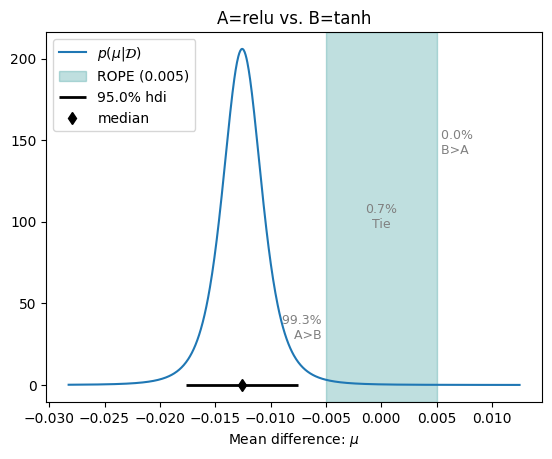

A=relu B=sigmoid: P(A wins)=0.9985 P(Tie)=0.0014 P(B wins)=0.0001 Effect Size=-9.53


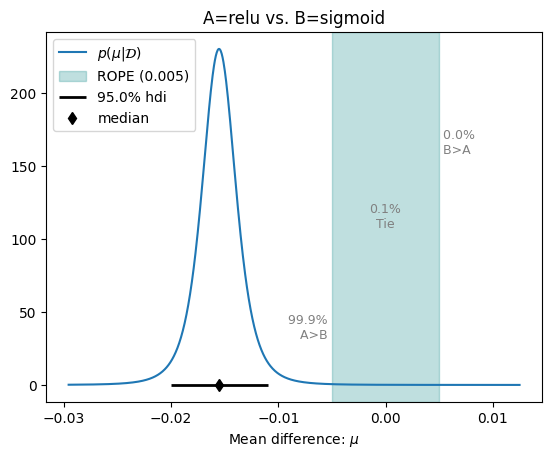

A=tanh B=sigmoid: P(A wins)=0.0792 P(Tie)=0.9196 P(B wins)=0.0012 Effect Size=-2.53


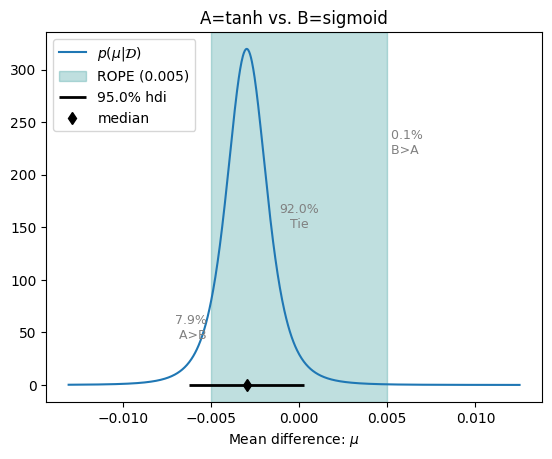

In [4]:
import json
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from part1.analysis import BenavoliCorrelatedT

rope = 0.005

with open("result1/activation_results.json") as f:
    activation_results = json.load(f)

for name, scores in activation_results.items():
    print(f"{name:8s} mean={np.mean(scores):.4f} std={np.std(scores):.4f}")

for name_a, name_b in combinations(activation_results, 2):
    posterior = BenavoliCorrelatedT(
        activation_results[name_a],
        activation_results[name_b],
        runs=1,
        names=[name_a, name_b],
    )
    p_a, p_tie, p_b = posterior.probs(rope)
    print(f"A={name_a} B={name_b}: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")

    fig, ax = posterior.plot(rope)
    fig.savefig(f"result1/compare_{name_a}_vs_{name_b}.png", dpi=150, bbox_inches="tight")
    plt.show()
